# Computer Vision

`torchvision` - główna biblioteka klasyfikacji obrazów w pytorch

`torch` rozpoczyna swoje operacje od momentu kiedy obrazy przetwarzane są w tensory, ale wcześniej odwołuje się też do innych bibliotek takich jak Pillow czy OpenCV

In [15]:
import torch
import torchvision
import torch.nn as nn
import torchvision.transforms as transforms
import pandas as pd
import numpy as np
import torch.nn.functional as F
import random
import matplotlib.pyplot as plt

In [16]:
def set_seed(seed):
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True)

set_seed(SEED)

# os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"  # wymagane przez niektóre operacje CUDA
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.mps.is_available() else "cpu")

## Zbiory danych
Razem z torchvision dostępne są standardowo wykorzystywane zbiory danych. Na potrzeby dzisiejszych ćwiczeń skorzystamy ze zbioru CIFAR-10 który ładujemy jako `torchvision.datasets.CIFAR10`.

In [17]:
batch_size = 32
classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

Z pikseli do tensorów:

In [18]:
trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True)
testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True)

sample = trainset[4]
print("first element:", sample)
sample[0].resize((128,128)).show()
np_sample = np.array(sample[0])
print(f"PIL -> Numpy: shape={np_sample.shape} | dtype={np_sample.dtype} | min={np_sample.min()} | max={np_sample.max()}")


/Users/kwasus/Desktop/STUDIA/SEM6/SSNE/Neural-Network-Concepts/.venv/lib/python3.13/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


first element: (<PIL.Image.Image image mode=RGB size=32x32 at 0x11E7CF570>, 1)
PIL -> Numpy: shape=(32, 32, 3) | dtype=uint8 | min=0 | max=254


In [19]:
transform = transforms.Compose([transforms.ToTensor()])
trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)

sample = trainset[4]
print(f"PIL -> Tensor: shape={sample[0].shape} | dtype={sample[0].dtype} | min={sample[0].min()} | max={sample[0].max()}")

all_samples = torch.stack([sample[0] for sample in trainset])
print(f"Data norm: mean={all_samples.mean():.4f} | std={all_samples.std():.4f}")
print(f"Data norm per channel: mean={all_samples.mean(axis=(0,2,3))} | std={all_samples.std(axis=(0,2,3))}")


/Users/kwasus/Desktop/STUDIA/SEM6/SSNE/Neural-Network-Concepts/.venv/lib/python3.13/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


PIL -> Tensor: shape=torch.Size([3, 32, 32]) | dtype=torch.float32 | min=0.0 | max=0.9960784316062927
Data norm: mean=0.4734 | std=0.2516
Data norm per channel: mean=tensor([0.4914, 0.4822, 0.4465]) | std=tensor([0.2470, 0.2435, 0.2616])


In [20]:
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))])

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)

all_samples = torch.stack([sample[0] for sample in trainset])
print(f"Data norm: mean={all_samples.mean():.4f} | std={all_samples.std():.4f}")
print(f"Data norm per channel: mean={all_samples.mean(axis=(0,2,3))} | std={all_samples.std(axis=(0,2,3))}")

Data norm: mean=-0.0000 | std=1.0000
Data norm per channel: mean=tensor([-1.2874e-06, -1.7074e-04,  1.1819e-04]) | std=tensor([1.0001, 0.9999, 1.0000])


In [21]:
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=16)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=16)

# get some random training images
images, labels = next(iter(trainloader))

/Users/kwasus/Desktop/STUDIA/SEM6/SSNE/Neural-Network-Concepts/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 12 (`cpuset` is not taken into account), which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/Users/kwasus/Desktop/STUDIA/SEM6/SSNE/Neural-Network-Concepts/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 12 (`cpuset` is not taken into account), which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get Da

In [22]:
import torch
from torch import Tensor

class Normalize(torch.nn.Module):
    def __init__(self, mean: list, std: list) -> None:
        super().__init__()
        self.mean: Tensor = torch.tensor(data=mean).view(-1, 1, 1)
        self.std: Tensor = torch.tensor(data=std).view(-1, 1, 1)

    def __call__(self, image: Tensor) -> Tensor:
        # image shape: [N_channels, H, W]
        pass

In [23]:
print(images.shape)
print(torchvision.utils.make_grid(images, nrow=8, padding=0).shape)

torch.Size([32, 3, 32, 32])
torch.Size([3, 128, 256])


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9894737..2.1264887].


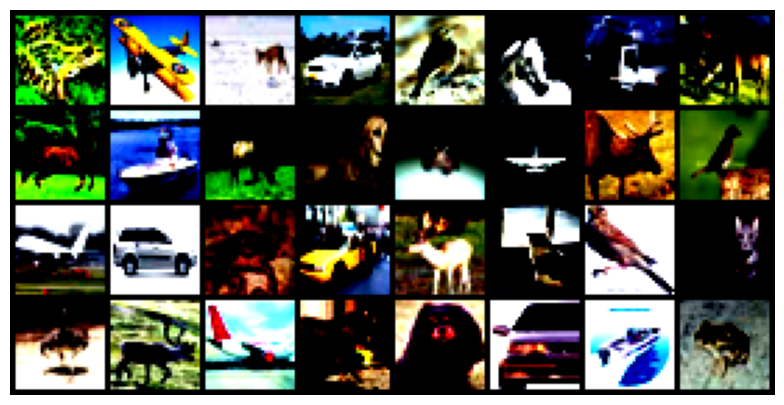

     frog     plane      deer       car      bird     horse     truck      deer
    horse      ship      deer       dog      frog     plane      deer      bird
    plane       car      frog       car      deer       cat      bird       cat
     bird      deer     plane     horse       dog       car      ship      frog


In [24]:
def imshow(img):
    plt.figure(figsize = (10,5))

    # ???
    img = img
    # ???

    npimg = img.numpy()
    plt.axis('off')
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()

imshow(torchvision.utils.make_grid(images, nrow=8))

for row_idx in range(0, batch_size, 8):
    print(' '.join('%9s' % classes[labels[j]] for j in range(row_idx, row_idx + 8)))

In [25]:
transform_output = transforms.Compose([
    # ???
    transforms.ToPILImage(),
    transforms.Resize((256,256))
])

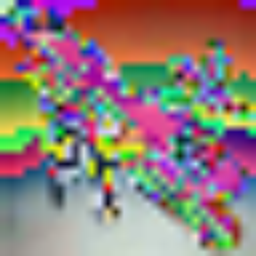

In [26]:
transform_output(images[1])

## Konwolucja

![](https://cs231n.github.io/assets/cnn/depthcol.jpeg)

Kolejność wymiarów:

In [27]:
print('[batch_size, channels, height, width]')
images[0:1].size()

[batch_size, channels, height, width]


torch.Size([1, 3, 32, 32])

conv: 
+ zmienia wymiarowość na height i width
+ zmienia liczbę kanałów

In [28]:
conv1 = nn.Conv2d(in_channels=3, out_channels=6, kernel_size=5).to(device)
conv1(images[0:1].to(device)).size()

torch.Size([1, 6, 28, 28])

+ kernel_size

In [29]:
conv1 = nn.Conv2d(in_channels=3, out_channels=6, kernel_size=(5,2)).to(device)
conv1(images[0:1].to(device)).size()

torch.Size([1, 6, 28, 31])

+ stride

In [30]:
conv1 = nn.Conv2d(in_channels=3, out_channels=6, kernel_size=5, stride=2).to(device)
conv1(images[0:1].to(device)).size()

torch.Size([1, 6, 14, 14])

+ padding

In [31]:
conv1 = nn.Conv2d(in_channels=3, out_channels=6, kernel_size=5, stride=2, padding=1).to(device)
conv1(images[0:1].to(device)).size()

torch.Size([1, 6, 15, 15])

In [32]:
conv1 = nn.Conv2d(in_channels=3, out_channels=2, kernel_size=2, stride=1, padding=[3,3], padding_mode='zeros').to(device)
out = conv1(images[0:1].to(device))
print(out.size())
out

torch.Size([1, 2, 37, 37])


tensor([[[[-0.2455, -0.2455, -0.2455,  ..., -0.2455, -0.2455, -0.2455],
          [-0.2455, -0.2455, -0.2455,  ..., -0.2455, -0.2455, -0.2455],
          [-0.2455, -0.2455, -0.3593,  ..., -0.3016, -0.2455, -0.2455],
          ...,
          [-0.2455, -0.2455, -0.3920,  ..., -0.0486, -0.2455, -0.2455],
          [-0.2455, -0.2455, -0.2455,  ..., -0.2455, -0.2455, -0.2455],
          [-0.2455, -0.2455, -0.2455,  ..., -0.2455, -0.2455, -0.2455]],

         [[ 0.0657,  0.0657,  0.0657,  ...,  0.0657,  0.0657,  0.0657],
          [ 0.0657,  0.0657,  0.0657,  ...,  0.0657,  0.0657,  0.0657],
          [ 0.0657,  0.0657,  0.2259,  ...,  0.3190,  0.0657,  0.0657],
          ...,
          [ 0.0657,  0.0657,  0.0457,  ...,  0.0449,  0.0657,  0.0657],
          [ 0.0657,  0.0657,  0.0657,  ...,  0.0657,  0.0657,  0.0657],
          [ 0.0657,  0.0657,  0.0657,  ...,  0.0657,  0.0657,  0.0657]]]],
       device='mps:0', grad_fn=<ConvolutionBackward0>)

In [33]:
for name, param in conv1.named_parameters():
    print(name, param.size())

weight torch.Size([2, 3, 2, 2])
bias torch.Size([2])


$$ \text{output\_size} = \lfloor \frac{\text{input\_size}-\text{kernel\_size}+2\cdot P}{\text{stride}} \rfloor + 1 $$

## Pooling

In [34]:
images[0:1].size()

torch.Size([1, 3, 32, 32])

In [35]:
pool1 = nn.MaxPool2d(kernel_size=2).to(device)
pool1(images[0:1].to(device)).size()

torch.Size([1, 3, 16, 16])

default: stride = kernel_size

In [36]:
pool1 = nn.MaxPool2d(kernel_size=2,stride=2).to(device)
pool1(images[0:1].to(device)).size()

torch.Size([1, 3, 16, 16])

In [37]:
pool1 = nn.MaxPool2d(kernel_size=2,stride=1).to(device)
pool1(images[0:1].to(device)).size()

torch.Size([1, 3, 31, 31])

+ max pooling:

In [38]:
mini_example = images[0:1,0,0:4,0:4]
mini_example

tensor([[[-0.2748, -0.2430, -0.4494, -0.3383],
         [-1.4338, -0.8305, -0.5923, -0.2430],
         [-1.4179, -1.8466, -1.4338,  0.0269],
         [-0.4812, -1.2274, -1.3226,  0.4238]]])

In [39]:
pool1 = nn.MaxPool2d(kernel_size=2).to(device)
pool1(mini_example.to(device))

tensor([[[-0.2430, -0.2430],
         [-0.4812,  0.4238]]], device='mps:0')

+ avg pooling

In [40]:
pool1 = nn.AvgPool2d(kernel_size=2).to(device)
pool1(mini_example.to(device))

tensor([[[-0.6955, -0.4058],
         [-1.2433, -0.5764]]], device='mps:0')

## Trenowanie sieci konwolucyjnej

In [41]:
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        ## Warstwa konwolucyjna
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=6, kernel_size=5, stride=1, padding=0)
        ## Warstwa max pooling 
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.pool2 = nn.MaxPool2d(2)    # kernel_size=2, stide=kernel_size (by default value)
        # !!!
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool1(F.relu(self.conv1(x)))
        x = self.pool2(F.relu(self.conv2(x)))
        # !!!
        x = torch.flatten(x, start_dim=1) # flatten all dimensions except batch
        # print(x.size())
        # !!!
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x

In [42]:
import torch.optim as optim

set_seed(42)

criterion = nn.CrossEntropyLoss()
net = Net().to(device)
optimizer = optim.Adam(net.parameters(), lr=0.001)

net

Net(
  (conv1): Conv2d(3, 6, kernel_size=(5, 5), stride=(1, 1))
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)

In [43]:
for epoch in range(5):  # loop over the dataset multiple times

    running_loss = 0.0
    for data in trainloader:
        inputs, labels = data
        inputs, labels = inputs.to(device), labels.to(device)

        # zero the parameter gradients
        optimizer.zero_grad()

        # forward + backward + optimize
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        # print statistics
        running_loss += loss.item()

    print('[%d/5] loss: %.3f' %
          (epoch+1 ,  running_loss / 2000))
    running_loss = 0.0

print('Finished Training')

[1/5] loss: 1.212
[2/5] loss: 0.987
[3/5] loss: 0.894
[4/5] loss: 0.829
[5/5] loss: 0.779
Finished Training


In [ ]:
images, labels = next(iter(testloader))
images = images[:4]

# print images
imshow(torchvision.utils.make_grid(images))
print('Targets: ', ' '.join('%5s' % classes[labels[j]] for j in range(4)))

In [ ]:
outputs = net(images.to(device))
outputs

In [ ]:
_, predicted = torch.max(outputs, 1)

print('Predicted: ', ' '.join('%5s' % classes[predicted[j]]
                              for j in range(4)))

In [ ]:
correct = 0
total = 0
with torch.no_grad():
    for data in testloader:
        images, labels = data
        images = images.to(device)
        outputs = net(images).cpu()

        # the class with the highest energy is what we choose as prediction
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print('Accuracy of the network on the 10000 test images: %d %%' % (
    100 * correct / total))

In [ ]:
correct_pred = {classname: 0 for classname in classes}
total_pred = {classname: 0 for classname in classes}

# again no gradients needed
with torch.no_grad():
    for data in testloader:
        images, labels = data    
        images = images.to(device)
        outputs = net(images).cpu()   
        _, predictions = torch.max(outputs, 1)
        # collect the correct predictions for each class
        for label, prediction in zip(labels, predictions):
            if label == prediction:
                correct_pred[classes[label]] += 1
            total_pred[classes[label]] += 1

  
# print accuracy for each class
for classname, correct_count in correct_pred.items():
    accuracy = 100 * float(correct_count) / total_pred[classname]
    print("Accuracy for class {:5s} is: {:.1f} %".format(classname, 
                                                   accuracy))

#### **Zadanie**: Spróbuj poprawić jakość klasyfikatora zmieniając parametry sieci

## Data augmentation

In [ ]:
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))])

batch_size = 4

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=False)

In [ ]:
plt.figure(figsize = (10,7))
images, labels = next(iter(trainloader))
images = images[:4]
labels = labels[:4]
images_orig = images.clone()

imshow(torchvision.utils.make_grid(images))

print(' '.join('%5s' % classes[labels[j]] for j in range(4)))

In [ ]:
transform = transforms.Compose(
    [transforms.CenterCrop(16),
     transforms.ToTensor(),
     transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))])

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=False)
images, labels = next(iter(trainloader))
imshow(torchvision.utils.make_grid(images_orig, padding=1))
imshow(torchvision.utils.make_grid(images, padding=1))

In [ ]:
transform = transforms.Compose(
    [transforms.RandomCrop(24),
     transforms.ToTensor(),
     transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))])

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=False)
images, labels = next(iter(trainloader))
imshow(torchvision.utils.make_grid(images_orig, padding=1))
imshow(torchvision.utils.make_grid(images, padding=1))

In [ ]:
transform = transforms.Compose(
    [transforms.RandomHorizontalFlip(0.5),
     transforms.ToTensor(),
     transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))])

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=False)
images, labels = next(iter(trainloader))
imshow(torchvision.utils.make_grid(images_orig, padding=1))
imshow(torchvision.utils.make_grid(images))

In [ ]:
transform = transforms.Compose(
    [transforms.RandomVerticalFlip(0.5),
     transforms.ToTensor(),
     transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))])

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=False)
images, labels = next(iter(trainloader))
imshow(torchvision.utils.make_grid(images_orig, padding=1))
imshow(torchvision.utils.make_grid(images))

In [ ]:
transform = transforms.Compose(
    [transforms.RandomRotation(24),
     transforms.ToTensor(),
     transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))])

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=False)
images, labels = next(iter(trainloader))
imshow(torchvision.utils.make_grid(images_orig, padding=1))
imshow(torchvision.utils.make_grid(images))

In [ ]:
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.RandomErasing(0.6),
     transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))])

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=False)
images, labels = next(iter(trainloader))
imshow(torchvision.utils.make_grid(images_orig, padding=1))
imshow(torchvision.utils.make_grid(images))

połączenie w całość:

In [ ]:
transform = transforms.Compose(
    [transforms.RandomHorizontalFlip(0.5),
     transforms.RandomVerticalFlip(0.5),
     transforms.RandomRotation(24),
     transforms.ToTensor(),
     transforms.RandomErasing(0.4),
     transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))])

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=False)
images, labels = next(iter(trainloader))
imshow(torchvision.utils.make_grid(images_orig, padding=1))
imshow(torchvision.utils.make_grid(images))

In [ ]:
transform = transforms.Compose(
    [transforms.RandomHorizontalFlip(0.5),
     transforms.RandomRotation(24),
     transforms.ToTensor(),
     transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))])

batch_size = 32

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True,num_workers=16)

In [ ]:
set_seed(42)
net = Net().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(net.parameters(), lr=0.001)

In [ ]:
for epoch in range(5):  # loop over the dataset multiple times

    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # get the inputs; data is a list of [inputs, labels]
        inputs, labels = data
        inputs, labels = inputs.to(device), labels.to(device)

        # zero the parameter gradients
        optimizer.zero_grad()

        # forward + backward + optimize
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        # print statistics
        running_loss += loss.item()

    print('[%d/5] loss: %.3f' %
          (epoch+1 ,  running_loss / 2000))
    running_loss = 0.0

print('Finished Training')

In [ ]:
correct = 0
total = 0
with torch.no_grad():
    for data in testloader:
        images, labels = data
        images = images.to(device)
        # calculate outputs by running images through the network 
        outputs = net(images).cpu()
        # the class with the highest energy is what we choose as prediction
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print('Accuracy of the network on the 10000 test images: %d %%' % (
    100 * correct / total))

In [ ]:
for epoch in range(10):  # loop over the dataset multiple times

    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # get the inputs; data is a list of [inputs, labels]
        inputs, labels = data
        inputs, labels = inputs.to(device), labels.to(device)

        # zero the parameter gradients
        optimizer.zero_grad()

        # forward + backward + optimize
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        # print statistics
        running_loss += loss.item()

    print('[%d/10] loss: %.3f' %
          (epoch+1 ,  running_loss / 2000))
    running_loss = 0.0

print('Finished Training')

In [ ]:
correct = 0
total = 0
with torch.no_grad():
    for data in testloader:
        images, labels = data
        images = images.to(device)
        # calculate outputs by running images through the network 
        outputs = net(images).cpu()
        # the class with the highest energy is what we choose as prediction
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print('Accuracy of the network on the 10000 test images: %d %%' % (
    100 * correct / total))

## Pretrained Networks

In [ ]:
import torchvision.models as models
resnet18 = models.resnet18()

![](https://www.oejournal.org/fileOEJ/journal/article/gdgc/2021/4/gdgc-48-4-200249-1-4.jpg)

In [ ]:
resnet18

**pytanie**: po co nam Conv2d z kernel_size=(1,1)?


In [ ]:
img = torch.randn((1, 3, 10, 10))
conv1 = nn.Conv2d(in_channels=3, out_channels=3, kernel_size=(1,1)).to(device)
conv1(img.to(device)).size()

In [ ]:
img = torch.randn((1, 3, 10, 10))
conv_depthwise = nn.Conv2d(in_channels=3, out_channels=3, kernel_size=(3,3), groups=3, padding=1).to(device)
conv_1x1 = nn.Conv2d(in_channels=3, out_channels=3, kernel_size=(1,1)).to(device)

output = conv_1x1(conv_depthwise(img.to(device)))
print(output.size())

In [ ]:
print(f"{conv_depthwise.weight.data.shape=}")
print(f"{conv_1x1.weight.data.shape=}")

### Porównanie liczby parametrów

In [ ]:
params_sum = 0
for params in net.parameters():
    params_sum+=params.view(-1).size(0)
params_sum

In [ ]:
params_sum = 0
for params in resnet18.parameters():
    params_sum+=params.view(-1).size(0)
params_sum

In [ ]:
densenet = models.densenet161()

In [ ]:
params_sum = 0
for params in densenet.parameters():
    params_sum+=params.view(-1).size(0)
params_sum

In [ ]:
# densenet

## Zanikanie gradientu w dłuuuuuugich sieciach

In [ ]:
import torch.nn as nn
import torch.nn.functional as F


class LongNet(nn.Module):
    def __init__(self):
        super().__init__()
        ## Warstwa konwolucyjna
        self.n_convs =  10
        n_channels = 10
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=n_channels, kernel_size=5, stride=1, padding=0)
        self.conv2 = nn.Conv2d(in_channels=n_channels, out_channels=n_channels, kernel_size=5, stride=1, padding=0)
        self.convs = [
            nn.Conv2d(in_channels=n_channels, out_channels=n_channels, kernel_size=5, stride=1, padding=2) for _ in range(self.n_convs)
        ]
        self.bns = [nn.BatchNorm2d(n_channels) for _ in range(self.n_convs)]
     
        ## Warstwa max pooling 
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)

        self.fc1 = nn.Linear(n_channels * 12 * 12, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        for i in range(self.n_convs):
            x = F.relu(self.convs[i](x))
            x = self.bns[i](x)
        x = self.pool1(x)
#         print(x.size())
        x = torch.flatten(x, 1) # flatten all dimensions except batch
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x


long_net = LongNet().to(device)
for conv in long_net.convs:
    conv.to(device)
for bn in long_net.bns:
    bn.to(device)
long_net

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(long_net.parameters(), lr=0.001)

In [ ]:
n_epochs = 5
for epoch in range(n_epochs):  # loop over the dataset multiple times

    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # get the inputs; data is a list of [inputs, labels]
        inputs, labels = data
        inputs, labels = inputs.to(device), labels.to(device)

        # zero the parameter gradients
        optimizer.zero_grad()

        # forward + backward + optimize
        outputs = long_net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        # print statistics
        running_loss += loss.item()

    print('[%d/%d] loss: %.3f' %
          (epoch+1 , n_epochs, running_loss / 2000))
    running_loss = 0.0
#     pd.DataFrame(long_net.conv1.weight.grad.cpu().detach().numpy().reshape(-1)).hist(bins=30)
    plt.hist(long_net.conv1.weight.grad.cpu().detach().numpy().reshape(-1),bins=50, label="first_conv",density=True,range=[-50,50])
    plt.hist(long_net.convs[9].weight.grad.cpu().detach().numpy().reshape(-1),bins=50, alpha=0.5, label="last_conv",density=True,range=[-50,50])
    plt.legend(loc='upper right')
    plt.show()
    plt.close()
    

print('Finished Training')

In [ ]:
class LongNet(nn.Module):
    def __init__(self):
        super().__init__()
        ## Warstwa konwolucyjna
        self.n_convs =  10
        n_channels = 10
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=n_channels, kernel_size=5, stride=1, padding=0)
        self.conv2 = nn.Conv2d(in_channels=n_channels, out_channels=n_channels, kernel_size=5, stride=1, padding=0)
        self.convs = [nn.Conv2d(in_channels=n_channels*2, out_channels=n_channels, kernel_size=5, stride=1, padding=2) for _ in range(self.n_convs)]
        self.bns = [nn.BatchNorm2d(n_channels) for _ in range(self.n_convs)]
     
        ## Warstwa max pooling 
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)

        self.fc1 = nn.Linear(n_channels * 12 * 12, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        res = F.relu(self.conv2(x))
        x = res
        for i in range(self.n_convs):
            x = torch.cat([x,res],dim=1)
            x = F.relu(self.convs[i](x))
            x = self.bns[i](x)
        x = self.pool1(x)
        x = torch.flatten(x, 1) # flatten all dimensions except batch
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x


long_net = LongNet().to(device)
for conv in long_net.convs:
    conv.to(device)
for bn in long_net.bns:
    bn.to(device)
long_net

In [ ]:
for epoch in range(n_epochs):  # loop over the dataset multiple times

    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # get the inputs; data is a list of [inputs, labels]
        inputs, labels = data
        inputs, labels = inputs.to(device), labels.to(device)

        # zero the parameter gradients
        optimizer.zero_grad()

        # forward + backward + optimize
        outputs = long_net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        # print statistics
        running_loss += loss.item()

    print('[%d/%d] loss: %.3f' %
          (epoch+1 , n_epochs, running_loss / 2000))
    running_loss = 0.0
    plt.hist(long_net.conv1.weight.grad.cpu().detach().numpy().reshape(-1),bins=50, label="first_conv",density=True,range=[-50,50])
    plt.hist(long_net.convs[9].weight.grad.cpu().detach().numpy().reshape(-1),bins=50, alpha=0.5, label="last_conv",density=True,range=[-50,50])
    plt.legend(loc='upper right')
    plt.show()
    plt.close()
    

print('Finished Training')

In [ ]:
from torchviz import make_dot

In [ ]:
make_dot(loss)

## Co tak naprawdę robią CNNy?

In [ ]:
def plot_filters_multi_channel(t):
    num_kernels = t.shape[0]

    num_cols = 12
    num_rows = num_kernels

    fig = plt.figure(figsize=(num_cols, num_rows))

    # looping through all the kernels
    for i in range(t.shape[0]):
        ax1 = fig.add_subplot(num_rows, num_cols, i + 1)

        # for each kernel, we convert the tensor to numpy
        npimg = np.array(t[i].numpy(), np.float32)
        # standardize the numpy image
        npimg = (npimg - np.mean(npimg)) / np.std(npimg)
        npimg = np.minimum(1, np.maximum(0, (npimg + 0.5)))
        npimg = npimg.transpose((1, 2, 0))
        ax1.imshow(npimg)
        ax1.axis("off")
        ax1.set_title(str(i))
        ax1.set_xticklabels([])
        ax1.set_yticklabels([])

    plt.tight_layout()
    plt.show()


def plot_filters_single_channel(t, n_first_neurons=None, n_first_channels=None):

    # kernels depth * number of kernels
    n_neurons = t.shape[0]
    n_channels = t.shape[1]
    if n_first_neurons is not None:
        n_neurons = n_first_neurons
        t = t[:n_first_neurons, :, :, :]
    if n_first_channels is not None:
        n_channels = n_first_channels
        t = t[:, :n_first_channels, :, :]

    nplots = n_neurons * n_channels
    ncols = 12

    nrows = 1 + nplots // ncols
    # convert tensor to numpy image
    npimg = np.array(t.numpy(), np.float32)

    count = 0
    fig = plt.figure(figsize=(ncols, nrows))

    # looping through all the kernels in each channel
    for i in range(t.shape[0]):
        for j in range(t.shape[1]):
            count += 1
            ax1 = fig.add_subplot(nrows, ncols, count)
            npimg = np.array(t[i, j].numpy(), np.float32)
            npimg = (npimg - np.mean(npimg)) / np.std(npimg)
            npimg = np.minimum(1, np.maximum(0, (npimg + 0.5)))
            ax1.imshow(npimg)
            ax1.set_title(str(i) + "," + str(j))
            ax1.axis("off")
            ax1.set_xticklabels([])
            ax1.set_yticklabels([])

    plt.tight_layout()
    plt.show()


def plot_weights(model, layer_num, single_channel=False, n_first_neurons=None, n_first_channels=None):

    # extracting the model features at the particular layer number
    layer = model.features[layer_num]
    print(layer.__class__)

    # checking whether the layer is convolution layer or not
    if isinstance(layer, nn.Conv2d):
        # getting the weight tensor data
        weight_tensor = model.features[layer_num].weight.data

        if single_channel:
            plot_filters_single_channel(
                weight_tensor, n_first_neurons=n_first_neurons, n_first_channels=n_first_channels
            )

        else:
            if weight_tensor.shape[1] == 3:
                plot_filters_multi_channel(weight_tensor)
            else:
                plot_filters_multi_channel(weight_tensor[:, :3, :, :])
                print("Plot limited to first 3 channels only")

    else:
        print("Can only visualize layers which are convolutional")

In [ ]:
alexnet = models.alexnet(weights="IMAGENET1K_V1")

![](https://viso.ai/wp-content/uploads/2024/04/alexNet-architecture.png)

In [ ]:
alexnet

**pytanie**: czym jest AdaptiveAvgPool2d?

In [ ]:
m = nn.AdaptiveAvgPool2d((5, 7))
input = torch.randn(1, 64, 8, 9)
output = m(input)
print(f"inp: {input.shape} -> out: {output.shape}")

m = nn.AdaptiveAvgPool2d(7)
input = torch.randn(1, 64, 10, 9)
output = m(input)
print(f"inp: {input.shape} -> out: {output.shape}")

m = nn.AdaptiveAvgPool2d((None, 7))
input = torch.randn(1, 64, 10, 9)
output = m(input)
print(f"inp: {input.shape} -> out: {output.shape}")

In [ ]:
plot_weights(alexnet, 0, single_channel = False)

In [ ]:
plot_weights(alexnet, 0, single_channel = True)

In [ ]:
plot_weights(alexnet, 3, single_channel = True, n_first_neurons=16, n_first_channels=12)

## Zadanie
Znajdź błędy i napraw model tak żeby działał i uczył się na zbiorze fashionMNIST. Podpowiedź:

https://x.com/ylecun/status/1459943933027487744

In [ ]:
import torch.optim as optim
import torch.nn as nn
import torch.nn.functional as F

In [ ]:
transform = transforms.Compose()
batch_size = 32

trainset = torchvision.datasets.FashionMNIST(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True)
testset = torchvision.datasets.FashionMNIST(root='./data', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False)

In [ ]:
class FashionNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=6, kernel_size=5, stride=1, padding=0)
        self.bn1 = nn.BatchNorm2d(6)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(3, 16, 5)
        self.bn2 = nn.BatchNorm2d(16)
        self.pool2 = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool1(F.relu(self.conv1(x)))
        x = self.bn1(x)
        x = self.pool2(F.relu(self.conv2(x)))
        x = self.bn2(x)
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x

In [ ]:
set_seed(42)
net = FashionNet().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(net.parameters(), lr=0.1)

In [ ]:
for epoch in range(5):  # loop over the dataset multiple times
    running_loss = 0.0
    for data in trainloader:
        # get the inputs; data is a list of [inputs, labels]
        inputs, labels = data
        inputs, labels = inputs.to(device), labels.to(device)

        # zero the parameter gradients
        optimizer.zero_grad()

        # forward + backward + optimize
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        # print statistics
        running_loss += loss.item()

    print(f"{epoch+1}/5, loss: {running_loss / 2000:.3f}")

print('Finished Training')

In [ ]:
correct = 0
total = 0
with torch.no_grad():
    for data in testloader:
        images, labels = data
        images = images.to(device)
        # calculate outputs by running images through the network 
        outputs = net(images).cpu()
        # the class with the highest energy is what we choose as prediction
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f"Accuracy: {100 * correct / total}%")

## Pre-trained models and Transfer Learning

![](https://framerusercontent.com/images/n6FZeNKpxNGHvLDBnWU1aHvs.jpeg?width=2672&height=1825)

In [ ]:
import torchvision
from torchvision.models import ResNet18_Weights
from torch import optim

In [ ]:
def init_resnet():
    resnet = torchvision.models.resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
    for param in resnet.parameters():
        param.requires_grad = False
    return resnet

net = init_resnet()

In [ ]:
net

In [ ]:
batch_size = 32

transform = transforms.Compose(
    [transforms.RandomHorizontalFlip(0.5),
     transforms.RandomRotation(24),
     transforms.ToTensor(),
     transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))])

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,download=True, transform=transform)
testset = torchvision.datasets.CIFAR10(root='./data', train=False,download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,shuffle=True, num_workers=16)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,shuffle=False, num_workers=16)

N_CLASSES = len(trainset.classes)

In [ ]:
def train_net(net, trainloader, testloader, criterion, optimizer, n_epochs=15):
    for epoch in range(n_epochs):
        net.train()
        running_loss = 0.0
        for i, data in enumerate(trainloader, 0):
            # get the inputs; data is a list of [inputs, labels]
            inputs, labels = data
            inputs, labels = inputs.to(device), labels.to(device)

            # zero the parameter gradients
            optimizer.zero_grad()

            # forward + backward + optimize
            outputs = net(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            # print statistics
            running_loss += loss.item()

        correct = 0
        total = 0
        net.eval()
        with torch.no_grad():
            for data in testloader:
                images, labels = data
                images = images.to(device)
                # calculate outputs by running images through the network 
                outputs = net(images).cpu()
                # the class with the highest energy is what we choose as prediction
                _, predicted = torch.max(outputs.data, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()

        print(f"[{epoch+1}/{n_epochs}] loss: {running_loss/2000:.3f} / acc: {100*correct/total:.1f}%")

    print('Finished Training')

In [ ]:
def init_resnet_with_fc(n_classes=N_CLASSES, freeze_pretrained=True):
    resnet = torchvision.models.resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
    for param in resnet.parameters():
        param.requires_grad = not freeze_pretrained
    resnet.fc = nn.Linear(resnet.fc.in_features, n_classes) # requires_grad by default!
    return resnet

+ trenowanie ostatniej warstwy:

In [ ]:
set_seed(42)
net = init_resnet_with_fc(N_CLASSES, freeze_pretrained=True)

criterion = nn.CrossEntropyLoss()
net = net.to(device)
optimizer = optim.Adam(net.parameters(), lr=1e-3)
train_net(net, trainloader, testloader, criterion, optimizer, n_epochs=10)

+ trenowanie wszystkich warstw:

In [ ]:
set_seed(42)
net = init_resnet_with_fc(N_CLASSES, freeze_pretrained=False)

criterion = nn.CrossEntropyLoss()
net = net.to(device)
optimizer = optim.Adam(net.parameters(), lr=3e-4)
train_net(net, trainloader, testloader, criterion, optimizer, n_epochs=5)

In [ ]:
set_seed(42)
net = init_resnet_with_fc(N_CLASSES, freeze_pretrained=False)

criterion = nn.CrossEntropyLoss()
net = net.to(device)

base_params = [p for name, p in net.named_parameters() if "fc" not in name]
optimizer = optim.Adam([
    {"params": base_params,          "lr": 3e-4},  # pretrained layers
    {"params": net.fc.parameters(),  "lr1": 1e-3},  # fresh head
])
train_net(net, trainloader, testloader, criterion, optimizer, n_epochs=5)